In [ ]:
"""
NeuroScan AI - Brain tumor MRI classification (30 classes)
Compares DenseNet121, ResNet50 and EfficientNetB0 (ImageNet transfer learning).


"""

# %% 1. IMPORTS & CONFIG ---------------------------------------------------------
import os
import random
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121, ResNet50, EfficientNetB0
from tensorflow.keras.applications.densenet import preprocess_input as densenet_pre
from tensorflow.keras.applications.resnet import preprocess_input as resnet_pre
from tensorflow.keras.applications.efficientnet import preprocess_input as effnet_pre

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
)

In [16]:
SEED = 42
IMG_SIZE = 256          # bigger than the native 224 -> finer MRI texture detail (T1/T1C+/T2 differences)
BATCH_SIZE = 32
HEAD_EPOCHS = 10        # phase 1: train only the new classification head
FINE_EPOCHS = 40        # phase 2: fine-tune the whole network
LR_HEAD = 1e-3
LR_FINE = 2e-5          # 5e-5 made val accuracy crash at the start of fine-tuning; 2e-5 is gentler

random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
print("GPUs found:", tf.config.list_physical_devices("GPU"))
PRED_DIR = 'preds'      # each model's test/val probabilities are saved here for the ensemble
os.makedirs(PRED_DIR, exist_ok=True)


GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [17]:
# %% 2. DATA LOADING -------------------------------------------------------------
# Downloads the dataset from Kaggle (needs a Kaggle account/API key the first time).
DATA_DIR = kagglehub.dataset_download("fernando2rad/brain-tumor-mri-images-30-classes")
print("Dataset path:", DATA_DIR)

# Each class is a folder (e.g. "Astrocytoma T1C+") holding .jpg images + .json metadata.
# We only need the images; the folder name is the label.
rows = []
for root, _, files in os.walk(DATA_DIR):
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            rows.append((os.path.join(root, f), os.path.basename(root)))

df = pd.DataFrame(rows, columns=["path", "label"])
class_names = sorted(df["label"].unique())
label_to_idx = {c: i for i, c in enumerate(class_names)}
df["y"] = df["label"].map(label_to_idx)
NUM_CLASSES = len(class_names)

print(f"Total images: {len(df)} | Classes: {NUM_CLASSES}")
assert NUM_CLASSES == 30, "Expected 30 class folders - check the dataset path/structure."

Dataset path: /kaggle/input/datasets/fernando2rad/brain-tumor-mri-images-30-classes
Total images: 11300 | Classes: 30


In [ ]:
# %% 3. VISUALIZATION ------------------------------------------------------------
# 3a. Class distribution
# 3a. Class distribution
plt.figure(figsize=(12, 6))
sns.countplot(
    x="label",
    data=df,
    order=class_names,
    color="steelblue"
)
plt.title("Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

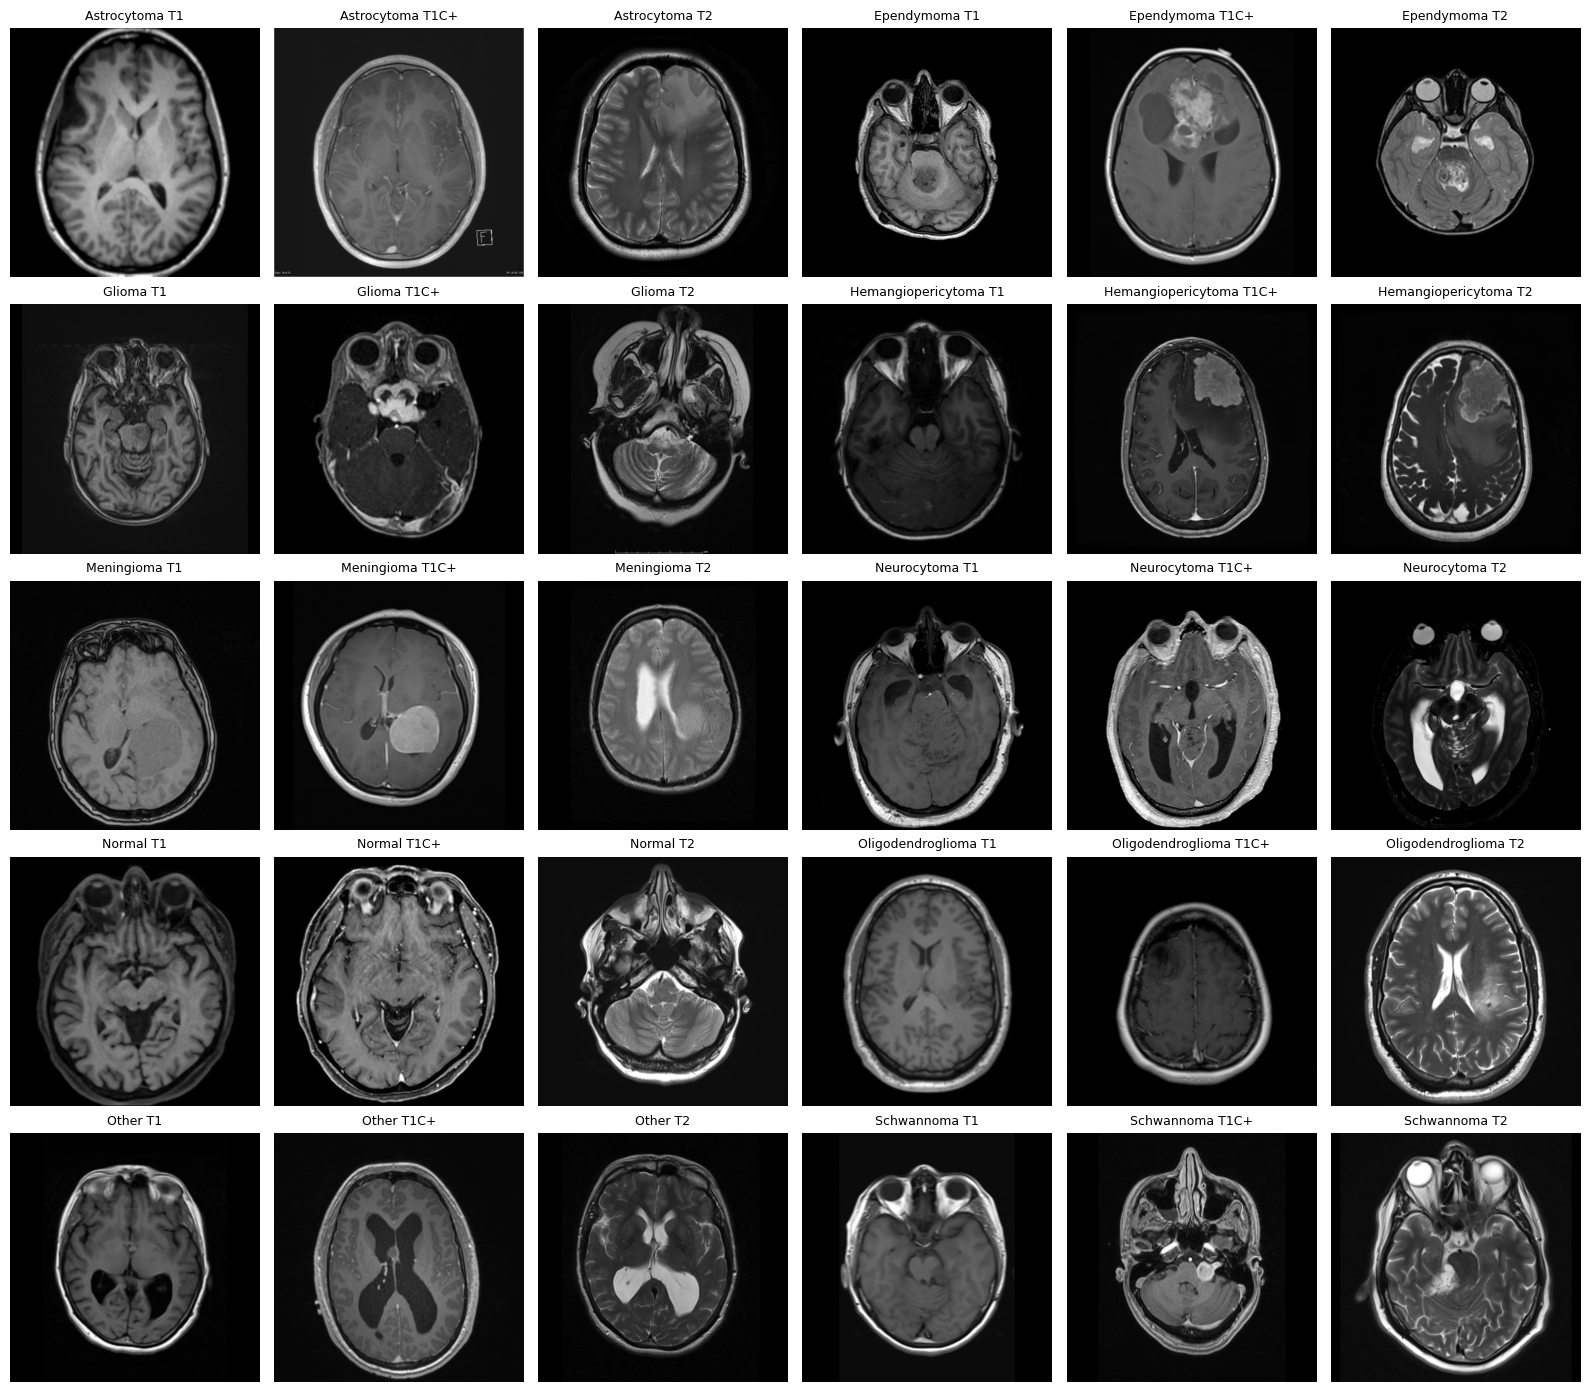

In [19]:
# 3b. One sample image from every class
fig, axes = plt.subplots(5, 6, figsize=(16, 14))
for ax, cls in zip(axes.ravel(), class_names):
    sample_path = df[df["label"] == cls].sample(1, random_state=SEED)["path"].iloc[0]
    ax.imshow(plt.imread(sample_path), cmap="gray")
    ax.set_title(cls, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [20]:
# %% 4. TRAIN / VALIDATION / TEST SPLIT -----------------------------------------
# Stratified 70 / 15 / 15 so every class appears in every split.
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["y"], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# Class weights help if some classes have fewer images than others.
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["y"])
class_weights = dict(enumerate(weights))

Train: 7910 | Val: 1695 | Test: 1695


In [21]:
# %% 5. PREPROCESSING (tf.data pipeline) ----------------------------------------
def load_image(path, label):
    """Read file -> 3-channel image -> resize to IMG_SIZE x IMG_SIZE."""
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(tf.round(img), tf.uint8)          # uint8 keeps the cache small
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return img, label


def make_dataset(frame, training):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].values, frame["y"].values))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).cache()
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(2000, seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)   # order is kept, so predictions line up with test_df

In [22]:
# %% 6. DATA AUGMENTATION --------------------------------------------------------
# These layers only act during training; at validation/test time they do nothing.
# Kept mild on purpose: MRI intensity and anatomy matter, so no heavy distortions.
def make_augmentation():
    return keras.Sequential(
        [
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.05),
            layers.RandomZoom(0.05),
            layers.RandomTranslation(0.03, 0.03),
            # no RandomContrast: T1 / T1C+ / T2 are told apart by intensity, so it blurs the classes
        ],
        name="augmentation",
    )

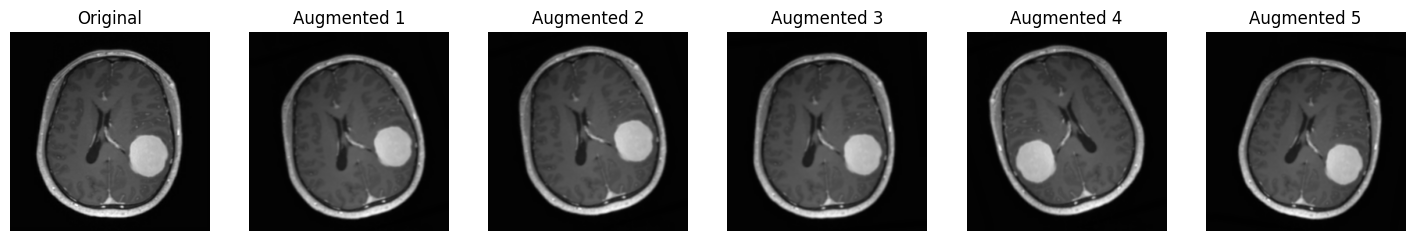

In [23]:
# Show what augmentation does to one image
sample_img = next(iter(train_ds))[0][:1]
aug = make_augmentation()
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
axes[0].imshow(sample_img[0].numpy().astype("uint8"))
axes[0].set_title("Original")
for i in range(1, 6):
    axes[i].imshow(aug(sample_img, training=True)[0].numpy().astype("uint8"))
    axes[i].set_title(f"Augmented {i}")
for ax in axes:
    ax.axis("off")
plt.show()

In [24]:
# %% 7. MODEL BUILDING -----------------------------------------------------------
# Each network has its own required input scaling, so it is applied inside the model.
ARCHITECTURES = {
    "DenseNet121": (DenseNet121, densenet_pre),
    "ResNet50": (ResNet50, resnet_pre),
    "EfficientNetB0": (EfficientNetB0, effnet_pre),
}


def build_model(name):
    base_cls, preprocess_fn = ARCHITECTURES[name]
    base = base_cls(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False                      # phase 1: backbone frozen

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = make_augmentation()(inputs)
    x = layers.Lambda(preprocess_fn, name="preprocess")(x)
    x = base(x, training=False)                 # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.1)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name), base

In [25]:
# %% 8. TRAINING (2 phases: train head -> fine-tune everything) ------------------
def get_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=8,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    ]


def compile_model(model, lr):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )


def train_model(name):
    model, base = build_model(name)

    # Phase 1: only the new classification head learns
    compile_model(model, LR_HEAD)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
                   class_weight=class_weights, callbacks=get_callbacks())

    # Phase 2: unfreeze the backbone (BatchNorm stays frozen) and fine-tune with a small LR
    base.trainable = True
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    compile_model(model, LR_FINE)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=FINE_EPOCHS,
                   class_weight=class_weights, callbacks=get_callbacks())

    history = {k: h1.history[k] + h2.history[k] for k in h1.history}
    return model, history

In [26]:
def predict_tta(model, ds):
    """Test-time augmentation: average the softmax of the image and its horizontal flip."""
    p1 = model.predict(ds, verbose=0)
    flipped = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
    p2 = model.predict(flipped, verbose=0)
    return (p1 + p2) / 2


# %% 9. EVALUATION HELPERS -------------------------------------------------------
def tumor_type(label):
    """'Astrocytoma T1C+' -> 'Astrocytoma' (ignores the MRI weighting)."""
    return label.rsplit(" ", 1)[0]


def evaluate_model(name, model):
    y_true = test_df["y"].values
    test_probs = predict_tta(model, test_ds)
    val_probs = predict_tta(model, val_ds)
    np.save(f"{PRED_DIR}/{name}_test.npy", test_probs)
    np.save(f"{PRED_DIR}/{name}_val.npy", val_probs)
    y_pred = np.argmax(test_probs, axis=1)

    # Extra view: accuracy at the 10-tumor-type level (ignoring T1/T1C+/T2)
    true_type = [tumor_type(class_names[i]) for i in y_true]
    pred_type = [tumor_type(class_names[i]) for i in y_pred]

    scores = {
        "Model": name,
        "Val Accuracy": accuracy_score(val_df["y"].values, np.argmax(val_probs, axis=1)),
        "Test Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Tumor-type Accuracy (10 cls)": accuracy_score(true_type, pred_type),
    }

    print(f"\n===== {name}: classification report =====")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    # Confusion matrix (row-normalised so each row shows recall per class)
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    plt.figure(figsize=(14, 12))
    sns.heatmap(cm_norm, cmap="Blues", xticklabels=class_names, yticklabels=class_names,
                vmin=0, vmax=1)
    plt.title(f"{name} - normalised confusion matrix (test set)")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks(rotation=90, fontsize=8)
    plt.yticks(fontsize=8)
    plt.tight_layout()
    plt.show()

    return scores

In [27]:
# %% 10. TRAINING - run ONE cell per model (each is independent; run them in any order)
results, histories = [], {}

def run_model(name):
    print(f"\n{'=' * 20} Training {name} {'=' * 20}")
    model, histories[name] = train_model(name)
    results.append(evaluate_model(name, model))
    model.save(f"{name}_brain_tumor.keras")
    keras.backend.clear_session()      # free GPU memory before the next model


### Command 1 - DenseNet121


==================== Training DenseNet121 ====================
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 206s 753ms/step - accuracy: 0.4392 - loss: 1.8630 - val_accuracy: 0.5504 - val_loss: 1.5292 - learning_rate: 0.0010
Epoch 2/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 57s 227ms/step - accuracy: 0.6351 - loss: 1.1047 - val_accuracy: 0.6525 - val_loss: 1.1833 - learning_rate: 0.0010
Epoch 3/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 56s 224ms/step - accuracy: 0.7067 - loss: 0.8813 - val_accuracy: 0.6985 - val_loss: 1.0085 - learning_rate: 0.0010
Epoch 4/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 56s 224ms/step - accuracy: 0.7458 - loss: 0.7691 - val_accuracy: 0.7180 - val_loss: 0.9393 - learning_rate: 0.0010
Epoch 5/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 56s 225ms/step - accuracy: 0.7723 - loss: 0.6664 - val_accuracy: 0.7233 - val_loss: 0.8869 - learning_rate: 0.0010
Epoch 6/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 56s 225ms/step - accuracy: 0.8009 - loss: 0.5973 - val_accuracy: 0.75

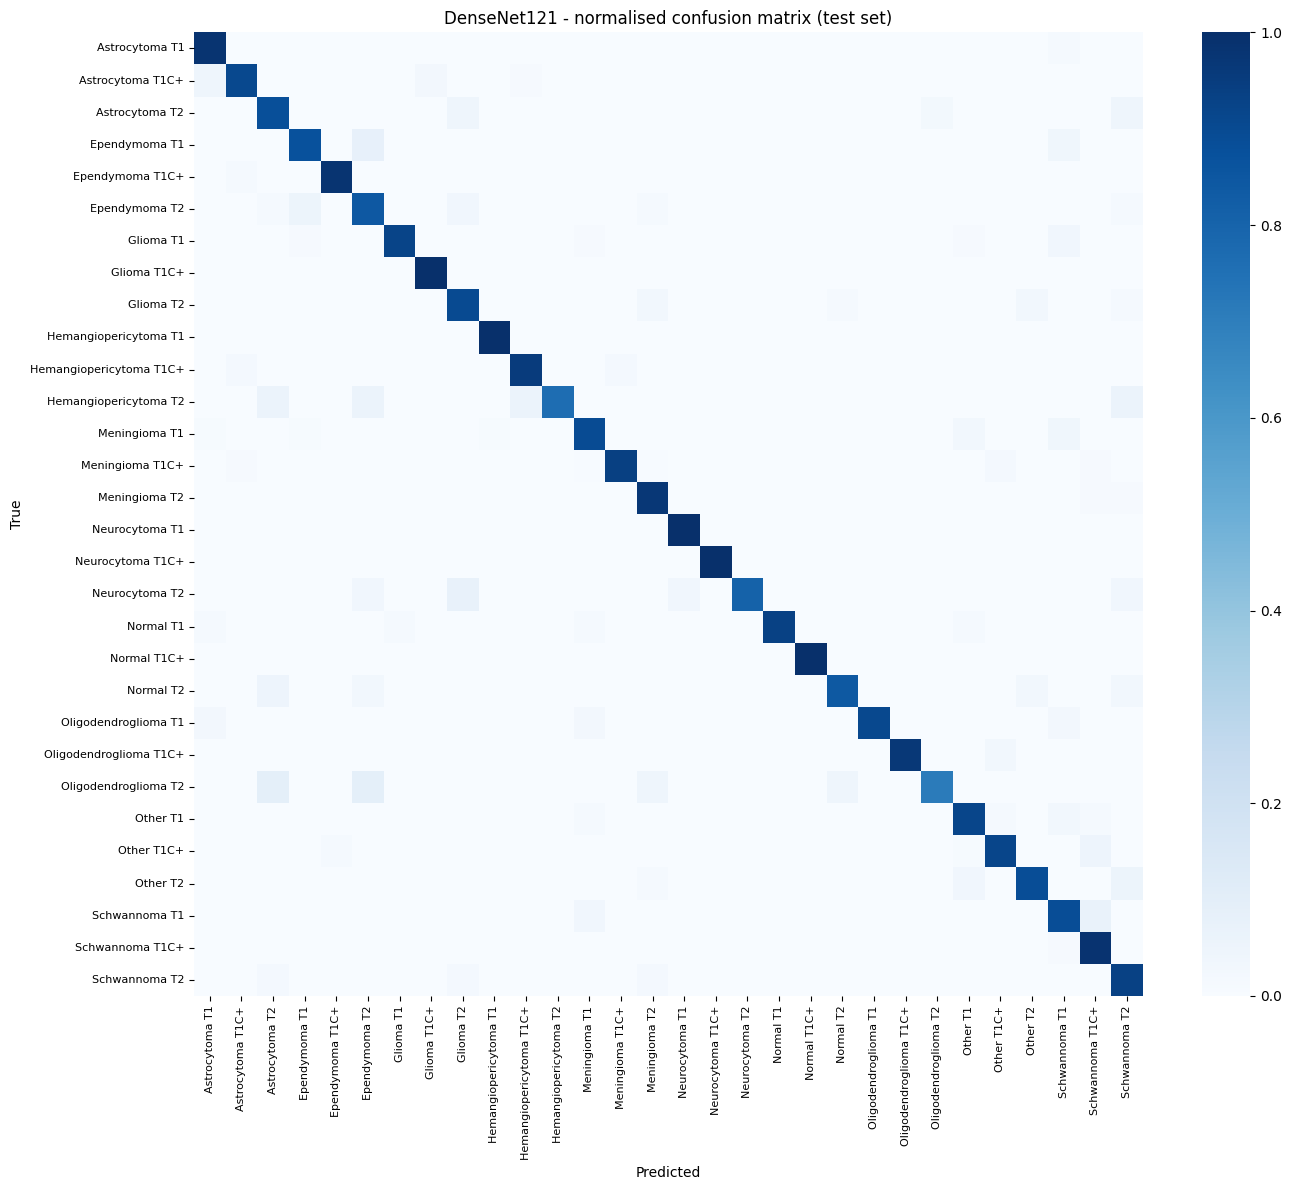

In [28]:
run_model("DenseNet121")

### Command 2 - ResNet50


==================== Training ResNet50 ====================
Epoch 1/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 62s 218ms/step - accuracy: 0.4606 - loss: 1.9422 - val_accuracy: 0.5906 - val_loss: 1.3654 - learning_rate: 0.0010
Epoch 2/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 51s 203ms/step - accuracy: 0.6702 - loss: 1.0185 - val_accuracy: 0.6920 - val_loss: 1.0515 - learning_rate: 0.0010
Epoch 3/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 51s 204ms/step - accuracy: 0.7494 - loss: 0.7747 - val_accuracy: 0.7227 - val_loss: 1.0060 - learning_rate: 0.0010
Epoch 4/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 51s 204ms/step - accuracy: 0.7924 - loss: 0.6543 - val_accuracy: 0.7404 - val_loss: 0.9373 - learning_rate: 0.0010
Epoch 5/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 51s 204ms/step - accuracy: 0.8201 - loss: 0.5801 - val_accuracy: 0.7581 - val_loss: 0.9451 - learning_rate: 0.0010
Epoch 6/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 51s 204ms/step - accuracy: 0.8407 - loss: 0.5125 - val_accuracy: 0.8012 - val_loss: 0.8103 - learning_rate: 0.0010
Epoch 7/1

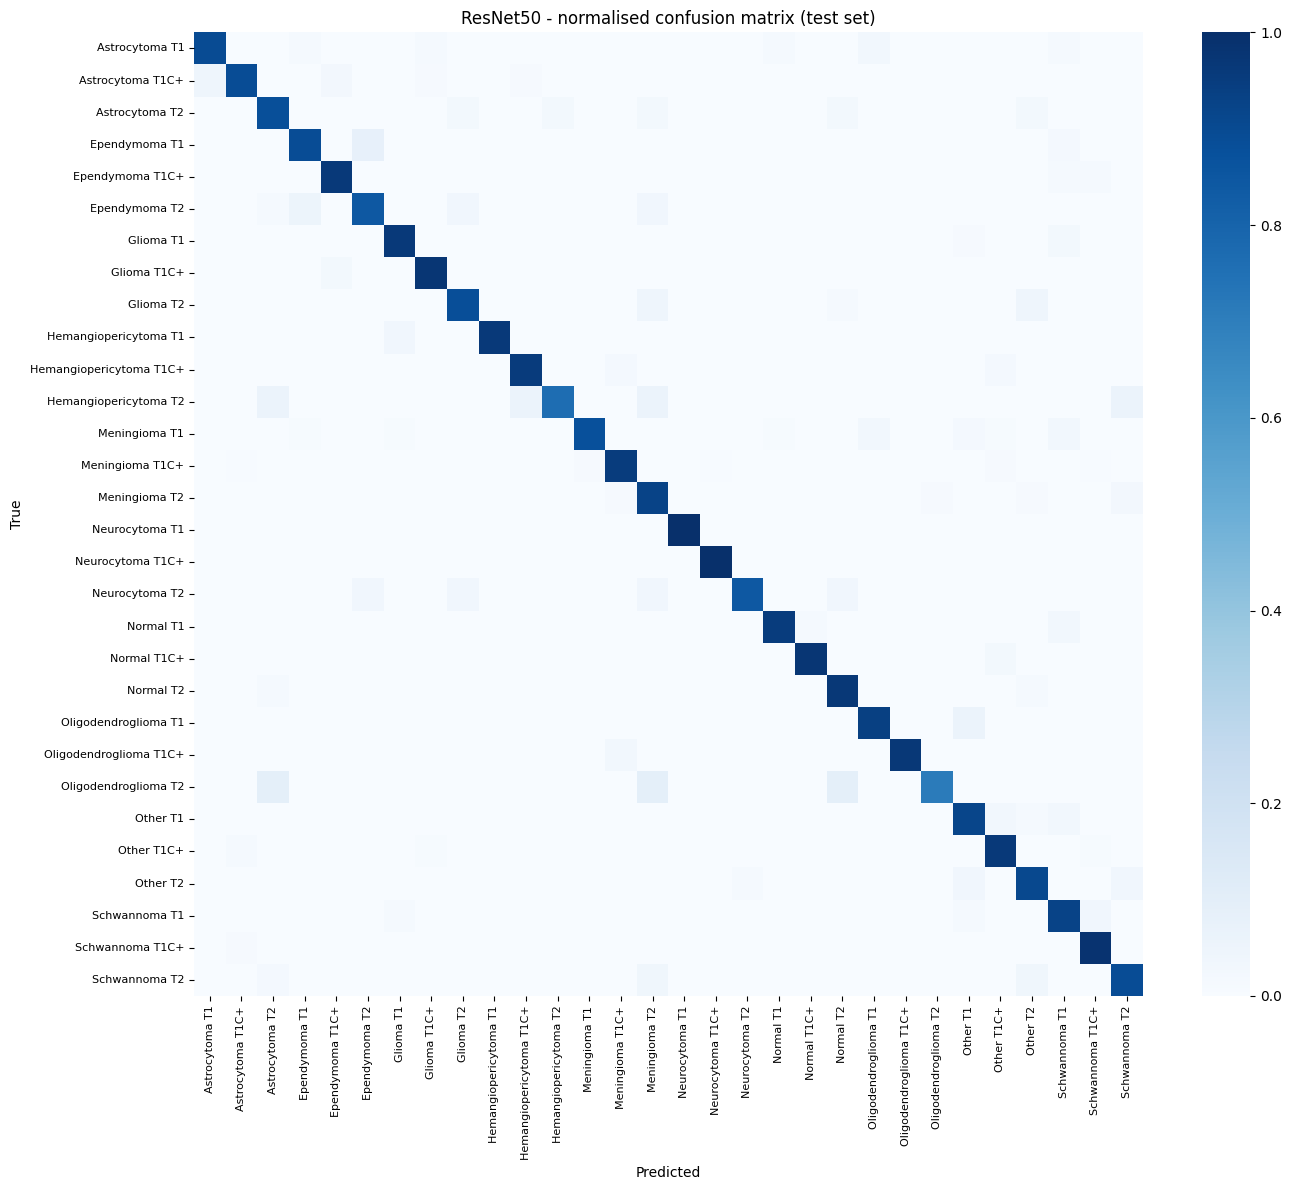

In [31]:
run_model("ResNet50")

### Command 3 - EfficientNetB0


==================== Training EfficientNetB0 ====================
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10


E0000 00:00:1793616112.111906      48 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


248/248 ━━━━━━━━━━━━━━━━━━━━ 45s 136ms/step - accuracy: 0.3971 - loss: 2.0961 - val_accuracy: 0.5198 - val_loss: 1.6785 - learning_rate: 0.0010
Epoch 2/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 30s 119ms/step - accuracy: 0.6047 - loss: 1.2546 - val_accuracy: 0.6395 - val_loss: 1.1948 - learning_rate: 0.0010
Epoch 3/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 30s 118ms/step - accuracy: 0.6719 - loss: 1.0031 - val_accuracy: 0.6602 - val_loss: 1.1659 - learning_rate: 0.0010
Epoch 4/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 30s 119ms/step - accuracy: 0.7231 - loss: 0.8541 - val_accuracy: 0.6861 - val_loss: 1.0904 - learning_rate: 0.0010
Epoch 5/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 30s 118ms/step - accuracy: 0.7491 - loss: 0.7796 - val_accuracy: 0.7027 - val_loss: 1.0328 - learning_rate: 0.0010
Epoch 6/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 30s 118ms/step - accuracy: 0.7795 - loss: 0.6819 - val_accuracy: 0.7233 - val_loss: 1.0026 - learning_rate: 0.0010
Epoch 7/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 30s 118ms/step - accuracy: 0.7880 - loss:

E0000 00:00:1793616434.831552      48 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


248/248 ━━━━━━━━━━━━━━━━━━━━ 103s 328ms/step - accuracy: 0.8684 - loss: 0.4377 - val_accuracy: 0.8136 - val_loss: 0.6988 - learning_rate: 2.0000e-05
Epoch 2/40
248/248 ━━━━━━━━━━━━━━━━━━━━ 79s 315ms/step - accuracy: 0.8954 - loss: 0.3646 - val_accuracy: 0.7894 - val_loss: 0.7475 - learning_rate: 2.0000e-05
Epoch 3/40
248/248 ━━━━━━━━━━━━━━━━━━━━ 78s 313ms/step - accuracy: 0.9100 - loss: 0.3280 - val_accuracy: 0.8124 - val_loss: 0.7192 - learning_rate: 2.0000e-05
Epoch 4/40
248/248 ━━━━━━━━━━━━━━━━━━━━ 79s 315ms/step - accuracy: 0.9204 - loss: 0.2964 - val_accuracy: 0.8230 - val_loss: 0.6817 - learning_rate: 6.0000e-06
Epoch 5/40
248/248 ━━━━━━━━━━━━━━━━━━━━ 79s 315ms/step - accuracy: 0.9278 - loss: 0.2807 - val_accuracy: 0.8248 - val_loss: 0.6785 - learning_rate: 6.0000e-06
Epoch 6/40
248/248 ━━━━━━━━━━━━━━━━━━━━ 78s 315ms/step - accuracy: 0.9320 - loss: 0.2742 - val_accuracy: 0.8230 - val_loss: 0.6658 - learning_rate: 6.0000e-06
Epoch 7/40
248/248 ━━━━━━━━━━━━━━━━━━━━ 78s 315ms/step -

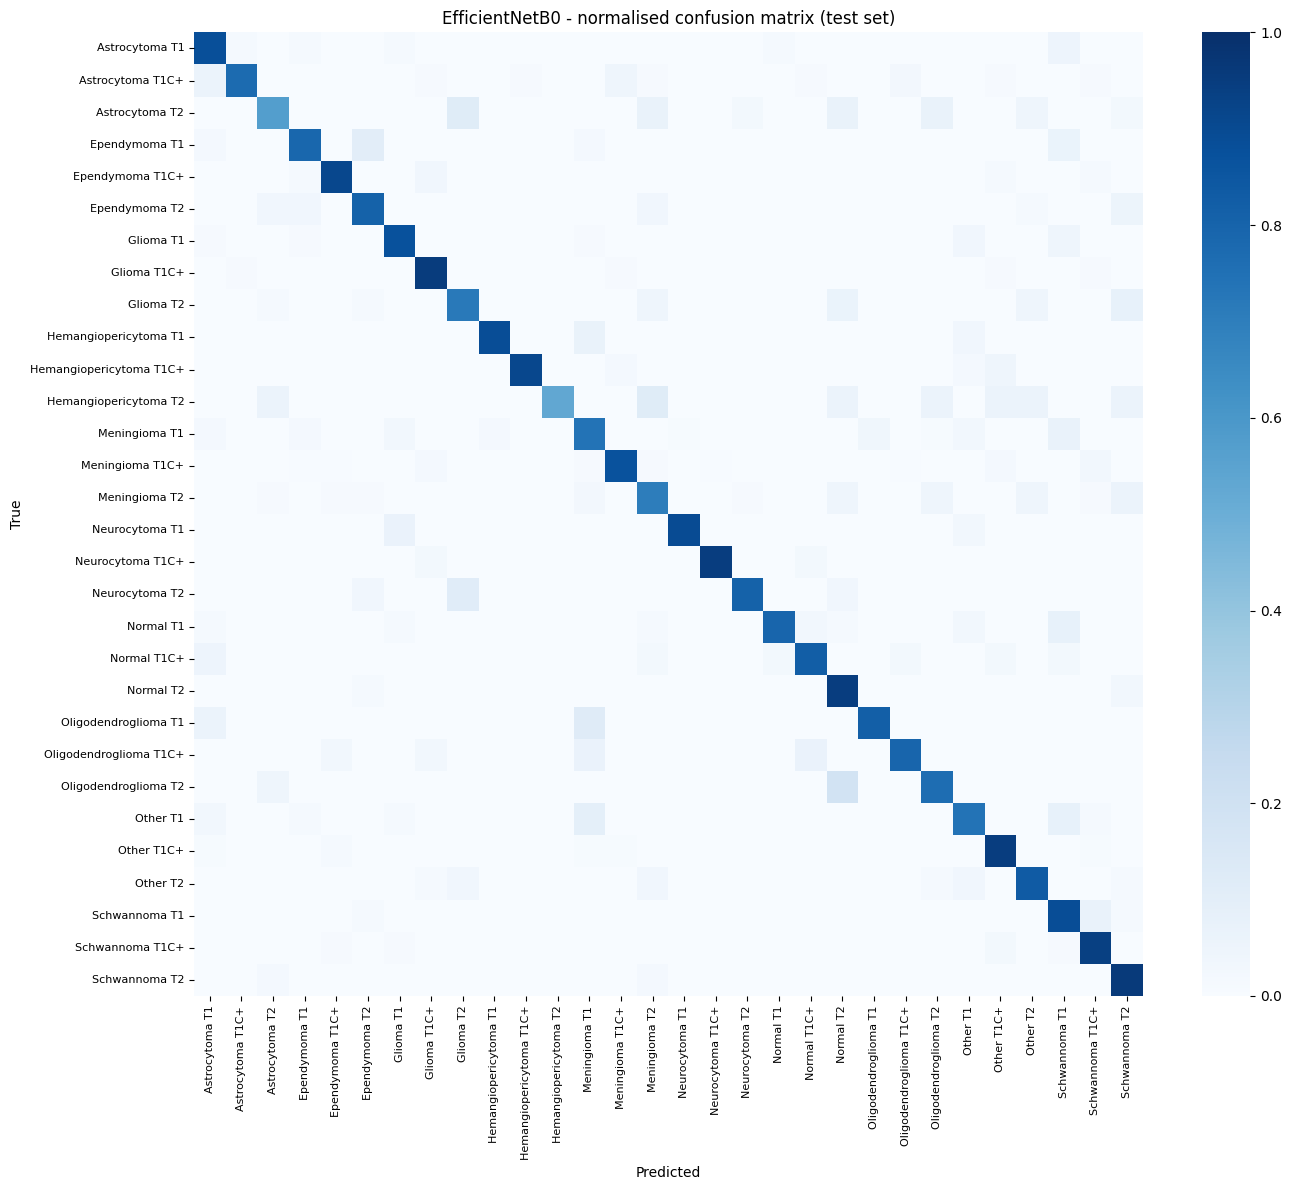

In [32]:
run_model("EfficientNetB0")